
# OEE Deteccion de microparadas con Machine Learning

## Objetivo

Este cuaderno de Jupyter tiene como objetivo analizar el registro de eventos y los indicadores OEE de una línea de producción, con el propósito de identificar **posibles microparadas que puedan estar afectando el desempeño productivo de la línea**.

Como primera aproximación, se implementa el algoritmo de detección de anomalías **Isolation Forest**, perteneciente al campo del aprendizaje automático no supervisado. La finalidad es identificar eventos o intervalos de operación que presenten comportamientos atípicos y que puedan estar asociados con pérdidas de producción. El modelo no utiliza como variables de entrada la descripción ni la clasificación del evento registrado, con el propósito de evitar que el algoritmo simplemente reproduzca las categorías previamente asignadas en los registros de producción.

El análisis se desarrolla mediante las siguientes etapas:

1. **Carga y validación de los registros de eventos**, verificando la estructura, consistencia y disponibilidad de los datos necesarios para el análisis.

2. **Limpieza y transformación de los datos**, incluyendo el tratamiento de fechas, duración de eventos, producción registrada y producción esperada.

3. **Construcción de variables operativas**, a partir de los datos disponibles, con el objetivo de representar las condiciones de funcionamiento de la línea y facilitar la identificación de comportamientos anómalos.

4. **Estimación de las pérdidas de producción asociadas con paradas no planificadas de corta duración**, buscando determinar cuáles de estos eventos podrían tener una incidencia relevante sobre el desempeño de la línea.

5. **Aplicación del algoritmo Isolation Forest**, mediante el cual se asigna una puntuación de anomalía a los eventos de parada. Esta puntuación permite diferenciar aquellos comportamientos que presentan características menos habituales dentro del conjunto de datos.

6. **Priorización de los posibles candidatos a microparadas**, ordenando los eventos de acuerdo con su nivel de anomalía y su posible impacto sobre la producción.

7. **Validación de los resultados obtenidos**, contrastando los candidatos identificados por el modelo con la información registrada en los eventos de producción. Esta etapa permite determinar si los comportamientos detectados tienen correspondencia con situaciones operativas reales.

8. **Análisis del impacto de las paradas identificadas**, considerando variables como la línea de producción, el turno, el producto fabricado y la causa registrada de la parada.

Mediante este procedimiento se busca determinar si las técnicas de aprendizaje automático pueden complementar el análisis tradicional del OEE y facilitar la identificación de eventos que, debido a su corta duración o recurrencia, podrían pasar desapercibidos en un análisis convencional. De esta manera, el análisis pretende generar información que pueda servir como punto de partida para identificar oportunidades de mejora en el proceso productivo.

**Limitación del análisis:** el conjunto de datos utilizado corresponde a un registro de eventos de producción. Por esta razón, el modelo puede identificar paradas cortas que hayan sido registradas explícitamente y períodos de producción que presenten un comportamiento anómalo, pero no puede reconstruir microparadas que nunca hayan sido registradas como eventos independientes. Para realizar una detección de microparadas con mayor resolución temporal, sería necesario complementar este análisis con datos provenientes directamente de los sistemas de control de la máquina, como señales del PLC o SCADA, estado de funcionamiento de la máquina, velocidad instantánea y contadores de producción.


## 1. Instalación de librerías


In [1]:
import sys
print('Python:', sys.executable)

Python: /opt/pyvenv/bin/python


## 2. Importación y definición

In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)

FILE_PATH = "/mnt/data/Data TVC 2025_Bruto.csv"

MICROSTOP_MAX_MINUTES = 5
MICROSTOP_MAX_SECONDS = MICROSTOP_MAX_MINUTES * 60

CONTAMINATION = 0.10

RANDOM_STATE = 42
OUTPUT_DIR = "/mnt/data/oee_ml_results_tvc2025"
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 3. Carga del csv

In [3]:
# Full TVC export: semicolon-separated CSV with a header row.
try:
    df = pd.read_csv(FILE_PATH, sep=';', header=0, encoding='utf-8', dtype=str)
except UnicodeDecodeError:
    df = pd.read_csv(FILE_PATH, sep=';', header=0, encoding='latin-1', dtype=str)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
df.head()


Rows: 31,664
Columns: 37


,EMPRESA,PLANTA,IDLINEA,LINEA,NUMERO_PLANTILLA,NPERS_X_LINEA,TOT_PERSONAS,COD_EVENTO,DES_EVENTO,CLASF_EVENTO,TASAGF,AGRUPACION,FECHA_REG,ANIO,MES,SEMANA,TURNO,INICIOEVENTO,FINEVENTO,TIEMPO_HR,NOLOTE,ORDENPRODUCCION,ART_CODIGO,ART_DESCRIPCIàN,AMBITO,FACTOR_CONVERSION,PRODUCCION,PRODUCCION_TM,INCONFORME,INCONFORME_TM,PR_ESPERADA,PR_ESPERADA_TM,VELOCIDADESTANDAR,SECCION,LIDER,PLANTILLAS_MES,PERS_PLAN_MES
0,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,4,Produccion,Produccion,0,1,6/2/2025,2025,2,6,1,6/2/2025 13:46,6/2/2025 14:59,1.218055556,78913,80014345,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,1033,1.02267,0,0,1169.333333,1.15764,16,Tozzomy,Jose Luis Mosquera Gavil nez,1,5
1,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,4,Produccion,Produccion,0,1,14/2/2025,2025,2,7,1,14/2/2025 7:15,14/2/2025 8:57,1.699166667,80499,80014652,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,1742,1.72458,0,0,1631.2,1.614888,16,Tozzomy,Jose Luis Mosquera Gavil nez,1,5
2,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,1120,Parada por Fin de semana,Feriado y Fin de Semana,0,2,10/5/2025,2025,5,19,2,10/5/2025 15:00,10/5/2025 23:00,8,96436,80017977,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,0,0,0,0,0,0,16,Tozzomy,Jose Luis Mosquera Gavil nez,(null),(null)
3,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,1531,Falta de Asignacion de personal,SIN ASIGNACIàN,0,2,7/5/2025,2025,5,19,2,7/5/2025 18:19,7/5/2025 23:00,4.671944444,95423,80017755,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,0,0,0,0,0,0,16,Tozzomy,Jose Luis Mosquera Gavil nez,(null),(null)
4,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,1531,Falta de Asignacion de personal,SIN ASIGNACIàN,0,2,25/2/2025,2025,2,9,2,25/2/2025 15:00,25/2/2025 23:00,8,82220,80015020,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,0,0,0,0,0,0,16,Tozzomy,Jose Luis Mosquera Gavil nez,1,5



## 4. Asignación de nombre de las columnas



In [4]:
COLUMN_NAMES = [
    'EMPRESA', 'PLANTA', 'IDLINEA', 'LINEA', 'NUMERO_PLANTILLA',
    'NPERS_X_LINEA', 'TOT_PERSONAS', 'COD_EVENTO', 'DES_EVENTO', 'CLASF_EVENTO',
    'TASAGF', 'AGRUPACION', 'FECHA_REG', 'ANIO', 'MES', 'SEMANA', 'TURNO',
    'INICIOEVENTO', 'FINEVENTO', 'TIEMPO_HR', 'NOLOTE', 'ORDENPRODUCCION',
    'ART_CODIGO', 'ART_DESCRIPCIÓN', 'AMBITO', 'FACTOR_CONVERSION',
    'PRODUCCION', 'PRODUCCION_TM', 'INCONFORME', 'INCONFORME_TM',
    'PR_ESPERADA', 'PR_ESPERADA_TM', 'VELOCIDADESTANDAR', 'SECCION',
    'LIDER', 'PLANTILLAS_MES', 'PERS_PLAN_MES'
]

if len(df.columns) != len(COLUMN_NAMES):
    raise ValueError(f"Expected {len(COLUMN_NAMES)} columns, but the file has {df.shape[1]}.")
df.columns = COLUMN_NAMES
df.head(3)


,EMPRESA,PLANTA,IDLINEA,LINEA,NUMERO_PLANTILLA,NPERS_X_LINEA,TOT_PERSONAS,COD_EVENTO,DES_EVENTO,CLASF_EVENTO,TASAGF,AGRUPACION,FECHA_REG,ANIO,MES,SEMANA,TURNO,INICIOEVENTO,FINEVENTO,TIEMPO_HR,NOLOTE,ORDENPRODUCCION,ART_CODIGO,ART_DESCRIPCIÓN,AMBITO,FACTOR_CONVERSION,PRODUCCION,PRODUCCION_TM,INCONFORME,INCONFORME_TM,PR_ESPERADA,PR_ESPERADA_TM,VELOCIDADESTANDAR,SECCION,LIDER,PLANTILLAS_MES,PERS_PLAN_MES
0,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,4,Produccion,Produccion,0,1,6/2/2025,2025,2,6,1,6/2/2025 13:46,6/2/2025 14:59,1.218055556,78913,80014345,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,1033,1.02267,0,0,1169.333333,1.15764,16,Tozzomy,Jose Luis Mosquera Gavil nez,1,5
1,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,4,Produccion,Produccion,0,1,14/2/2025,2025,2,7,1,14/2/2025 7:15,14/2/2025 8:57,1.699166667,80499,80014652,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,1742,1.72458,0,0,1631.2,1.614888,16,Tozzomy,Jose Luis Mosquera Gavil nez,1,5
2,Planta Matriz,PRODUCCION LIQUIDOS FORKY,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,1,5,5,1120,Parada por Fin de semana,Feriado y Fin de Semana,0,2,10/5/2025,2025,5,19,2,10/5/2025 15:00,10/5/2025 23:00,8,96436,80017977,110000263,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,1,0.99,0,0,0,0,0,0,16,Tozzomy,Jose Luis Mosquera Gavil nez,(null),(null)


## 5. Limpieza de información

In [5]:

# Normalize empty/null strings.
df = df.replace({"(null)": np.nan, "null": np.nan, "": np.nan})

# Convert numeric columns.
numeric_cols = [
    'IDLINEA', 'NUMERO_PLANTILLA', 'NPERS_X_LINEA', 'TOT_PERSONAS', 'COD_EVENTO',
    'TASAGF', 'AGRUPACION', 'ANIO', 'MES', 'SEMANA', 'TURNO', 'TIEMPO_HR',
    'NOLOTE', 'ORDENPRODUCCION', 'ART_CODIGO', 'AMBITO', 'FACTOR_CONVERSION',
    'PRODUCCION', 'PRODUCCION_TM', 'INCONFORME', 'INCONFORME_TM', 'PR_ESPERADA',
    'PR_ESPERADA_TM', 'VELOCIDADESTANDAR', 'PLANTILLAS_MES', 'PERS_PLAN_MES'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Dates/times.
df["FECHA_REG"] = pd.to_datetime(df["FECHA_REG"], dayfirst=True, errors="coerce")
df["INICIOEVENTO"] = pd.to_datetime(df["INICIOEVENTO"], dayfirst=True, errors="coerce")
df["FINEVENTO"] = pd.to_datetime(df["FINEVENTO"], dayfirst=True, errors="coerce")

# Recalculate duration from timestamps when possible.
df["DURACION_SEG"] = (df["FINEVENTO"] - df["INICIOEVENTO"]).dt.total_seconds()

# The source TIEMPO_HR has some obvious legacy/bad values in the example.
# Keep the source value but prefer timestamp duration for analytics when available and non-negative.
df["DURACION_SEG"] = np.where(
    df["DURACION_SEG"].ge(0),
    df["DURACION_SEG"],
    df["TIEMPO_HR"] * 3600
)

df["DURACION_MIN"] = df["DURACION_SEG"] / 60

df["HORA_INICIO"] = df["INICIOEVENTO"].dt.hour + df["INICIOEVENTO"].dt.minute / 60
df["DIA_SEMANA"] = df["INICIOEVENTO"].dt.dayofweek

# Basic flags.
df["ES_PRODUCCION"] = df["CLASF_EVENTO"].eq("Produccion")
df["ES_NO_PROGRAMADO"] = df["CLASF_EVENTO"].eq("Paro No Programado")
df["ES_PROGRAMADO"] = df["CLASF_EVENTO"].eq("Paro Programado")

# Production performance. Only meaningful when expected production > 0.
df["PERFORMANCE_RATIO"] = np.where(
    (df["ES_PRODUCCION"]) & (df["PR_ESPERADA"] > 0),
    df["PRODUCCION"] / df["PR_ESPERADA"],
    np.nan,
)

df["PERFORMANCE_LOSS_RATIO"] = np.clip(1 - df["PERFORMANCE_RATIO"], 0, None)
df["PRODUCCION_PERDIDA_UNIDADES"] = np.clip(df["PR_ESPERADA"] - df["PRODUCCION"], 0, None)

display(df[["IDLINEA", "DES_EVENTO", "CLASF_EVENTO", "INICIOEVENTO", "FINEVENTO", "DURACION_MIN", "PRODUCCION", "PR_ESPERADA", "PERFORMANCE_RATIO"]].head(10))


,IDLINEA,DES_EVENTO,CLASF_EVENTO,INICIOEVENTO,FINEVENTO,DURACION_MIN,PRODUCCION,PR_ESPERADA,PERFORMANCE_RATIO
0,8005,Produccion,Produccion,2025-02-06 13:46:00,2025-02-06 14:59:00,73.0,1033,1169.333333,0.883409
1,8005,Produccion,Produccion,2025-02-14 07:15:00,2025-02-14 08:57:00,102.0,1742,1631.200000,1.067925
2,8005,Parada por Fin de semana,Feriado y Fin de Semana,2025-05-10 15:00:00,2025-05-10 23:00:00,480.0,0,0.000000,NaN
3,8005,Falta de Asignacion de personal,SIN ASIGNACIàN,2025-05-07 18:19:00,2025-05-07 23:00:00,281.0,0,0.000000,NaN
4,8005,Falta de Asignacion de personal,SIN ASIGNACIàN,2025-02-25 15:00:00,2025-02-25 23:00:00,480.0,0,0.000000,NaN
5,8005,Produccion,Produccion,2025-02-21 15:00:00,2025-02-21 17:44:00,164.0,2457,2627.466667,0.935121
6,8005,Falta de Asignacion de personal,SIN ASIGNACIàN,2025-02-21 07:00:00,2025-02-21 07:00:00,0.0,0,0.000000,NaN
7,8005,Falta de Asignacion de personal,SIN ASIGNACIàN,2025-05-23 15:00:00,2025-05-23 15:00:00,0.0,0,0.000000,NaN
8,8005,Personal Asignado a otra linea,Paro Programado,2025-03-24 15:25:00,2025-03-24 23:00:00,455.0,0,0.000000,NaN
9,8005,Personal Asignado a otra linea,Paro Programado,2025-05-06 07:12:00,2025-05-06 15:00:00,468.0,0,0.000000,NaN


## 6. Revisión de datos y formatos

In [6]:

print("Missing values in key fields:")
display(df[["IDLINEA", "INICIOEVENTO", "FINEVENTO", "DURACION_SEG", "CLASF_EVENTO"]].isna().sum())

print("\nEvent classes:")
display(df["CLASF_EVENTO"].value_counts(dropna=False))

print("\nEvent descriptions:")
display(df["DES_EVENTO"].value_counts(dropna=False).head(20))

print("\nRows with negative or missing duration:")
print(df.loc[df["DURACION_SEG"].isna() | df["DURACION_SEG"].lt(0), ["INICIOEVENTO", "FINEVENTO", "TIEMPO_HR", "DES_EVENTO"]])


Missing values in key fields:


IDLINEA         0
INICIOEVENTO    0
FINEVENTO       0
DURACION_SEG    0
CLASF_EVENTO    0
dtype: int64


Event classes:


CLASF_EVENTO
Produccion                 12839
Paro No Programado         10882
Paro Programado             6250
SIN ASIGNACIàN               953
Feriado y Fin de Semana      676
Mantenimiento Global          55
Flta. Ord. Produccion          9
Name: count, dtype: int64


Event descriptions:


DES_EVENTO
Produccion                            12839
Calibracion   Preparacion de Linea     4420
Atascamiento de Proceso                2841
Paradas Operacionales Imprevistas      1828
Limpieza de linea                      1545
Alimentacion en comedor                1075
Cambio de Rollos  Lamina               1040
Falta de Asignacion de personal         953
Cambio de Producto                      740
Arranque   Parada                       614
Cambio de Formato Molde                 610
Parada por Fin de semana                550
Falla de fajilladora                    401
Cambio de Consumible                    283
Falta de Envases                        225
Fallas Mecanicas de Procesos            147
Fallas de Equipos de Pesaje             143
Parada por Pruebas                      137
Parada por Feriado                      126
Falta de Materiales de empaques         118
Name: count, dtype: int64


Rows with negative or missing duration:
Empty DataFrame
Columns: [INICIOEVENTO, FINEVENTO, TIEMPO_HR, DES_EVENTO]
Index: []


## 7. Estimación de la tasa de producción esperada

En el caso de una parada registrada, el campo `PR_ESPERADA` presenta un valor de cero en el conjunto de datos utilizado. Por esta razón, para estimar cuántas unidades podrían haberse producido durante una parada de corta duración, se calcula una **tasa de producción normal** a partir de los registros reales de producción.

Para obtener una estimación representativa, se establece una jerarquía de búsqueda de acuerdo con el nivel de información disponible. En primer lugar, se considera la combinación **línea + producto + turno**. Si no existe suficiente información para realizar la estimación bajo este criterio, se amplía progresivamente el nivel de referencia a **línea + producto**, posteriormente a **línea** y, finalmente, se utiliza una **tasa de producción global**.

Esta estrategia permite utilizar la referencia de producción más específica disponible para cada evento, reduciendo el riesgo de realizar estimaciones con tasas que no representen adecuadamente las condiciones reales de operación.

In [7]:

prod = df.loc[df["ES_PRODUCCION"] & df["PR_ESPERADA"].gt(0)].copy()
prod["EXPECTED_RATE_UNITS_HR"] = prod["PR_ESPERADA"] / prod["TIEMPO_HR"].replace(0, np.nan)
prod["EXPECTED_RATE_UNITS_HR"] = prod["EXPECTED_RATE_UNITS_HR"].replace([np.inf, -np.inf], np.nan)

rate_line_product_shift = prod.groupby(["IDLINEA", "ART_CODIGO", "TURNO"])["EXPECTED_RATE_UNITS_HR"].median()
rate_line_product = prod.groupby(["IDLINEA", "ART_CODIGO"])["EXPECTED_RATE_UNITS_HR"].median()
rate_line = prod.groupby(["IDLINEA"])["EXPECTED_RATE_UNITS_HR"].median()
global_rate = prod["EXPECTED_RATE_UNITS_HR"].median()

keys_lps = list(zip(df["IDLINEA"], df["ART_CODIGO"], df["TURNO"]))
keys_lp = list(zip(df["IDLINEA"], df["ART_CODIGO"]))

rate_values = []
for k1, k2, line in zip(keys_lps, keys_lp, df["IDLINEA"]):
    if k1 in rate_line_product_shift.index:
        rate_values.append(rate_line_product_shift.loc[k1])
    elif k2 in rate_line_product.index:
        rate_values.append(rate_line_product.loc[k2])
    elif line in rate_line.index:
        rate_values.append(rate_line.loc[line])
    else:
        rate_values.append(global_rate)

df["EXPECTED_RATE_UNITS_HR"] = rate_values

df["ESTIMATED_LOSS_UNITS"] = np.where(
    df["ES_NO_PROGRAMADO"],
    df["DURACION_SEG"] / 3600 * df["EXPECTED_RATE_UNITS_HR"],
    0,
)

df[["IDLINEA", "ART_CODIGO", "TURNO", "DURACION_MIN", "EXPECTED_RATE_UNITS_HR", "ESTIMATED_LOSS_UNITS"]].head()


,IDLINEA,ART_CODIGO,TURNO,DURACION_MIN,EXPECTED_RATE_UNITS_HR,ESTIMATED_LOSS_UNITS
0,8005,110000263.0,1,73.0,960.0,0.0
1,8005,110000263.0,1,102.0,960.0,0.0
2,8005,110000263.0,2,480.0,960.0,0.0
3,8005,110000263.0,2,281.0,960.0,0.0
4,8005,110000263.0,2,480.0,960.0,0.0


## 8. Exploración de paradas no planificadas de corta duración

Para este análisis se establece inicialmente un umbral de **5 minutos** para identificar paradas no planificadas de corta duración. Sin embargo, este valor debe considerarse como una **regla de negocio inicial y no como un criterio científico definitivo**.

En el desarrollo de la investigación, se deberá evaluar la sensibilidad de los resultados frente a diferentes umbrales de duración, considerando, por ejemplo, **1, 3, 5 y 10 minutos**. Esta comparación permitirá determinar cómo cambia la cantidad de eventos identificados y su impacto estimado sobre la producción al modificar el límite utilizado para definir una parada de corta duración.

A partir de estos resultados, se podrá seleccionar y justificar el umbral más adecuado para el contexto de la línea de producción analizada, procurando que la definición adoptada tenga sustento tanto en el comportamiento observado en los datos como en las características operativas del proceso productivo.

In [8]:

stop_candidates = df.loc[
    df["ES_NO_PROGRAMADO"] & df["DURACION_SEG"].between(0, MICROSTOP_MAX_SECONDS, inclusive="both")
].copy()

print(f"Unplanned stops: {df['ES_NO_PROGRAMADO'].sum():,}")
print(f"Short-stop candidates (<= {MICROSTOP_MAX_MINUTES} min): {len(stop_candidates):,}")

display(
    stop_candidates[
        ["IDLINEA", "LINEA", "DES_EVENTO", "INICIOEVENTO", "DURACION_MIN", "EXPECTED_RATE_UNITS_HR", "ESTIMATED_LOSS_UNITS", "TURNO"]
    ].sort_values("ESTIMATED_LOSS_UNITS", ascending=False)
)


Unplanned stops: 10,882
Short-stop candidates (<= 5 min): 7,334


,IDLINEA,LINEA,DES_EVENTO,INICIOEVENTO,DURACION_MIN,EXPECTED_RATE_UNITS_HR,ESTIMATED_LOSS_UNITS,TURNO
18626,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,2025-04-13 23:05:00,5.0,6240.000001,520.0,3
6763,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,2025-04-13 02:23:00,5.0,6240.000001,520.0,3
26727,8001,ENVASADO BOTELLA ROTATIVA DESINF,Calibracion Preparacion de Linea,2025-04-30 05:28:00,5.0,6240.000001,520.0,3
10797,8001,ENVASADO BOTELLA ROTATIVA DESINF,Calibracion Preparacion de Linea,2025-01-22 01:12:00,5.0,6240.000001,520.0,3
26821,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,2025-04-13 23:53:00,5.0,6240.000001,520.0,3
...,...,...,...,...,...,...,...,...
7647,8001,ENVASADO BOTELLA ROTATIVA DESINF,Calibracion Preparacion de Linea,2025-04-07 13:18:00,0.0,6240.000000,0.0,1
7629,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,2025-04-15 22:00:00,0.0,6240.000000,0.0,2
7812,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,2025-04-04 11:58:00,0.0,6240.000000,0.0,1
7783,8001,ENVASADO BOTELLA ROTATIVA DESINF,Calibracion Preparacion de Linea,2025-03-10 15:11:00,0.0,6240.000000,0.0,2


## 9. Modelo de aprendizaje automático: Isolation Forest

Para esta etapa del análisis se propone utilizar el algoritmo de aprendizaje automático **Isolation Forest**, debido a que inicialmente no se dispone de un conjunto de datos confiable en el que las microparadas hayan sido identificadas y clasificadas previamente por un experto. Por esta razón, se opta por un enfoque de **aprendizaje no supervisado**, mediante el cual se busca identificar comportamientos que se diferencien de los patrones habituales registrados en la línea de producción.

Desde la perspectiva de este trabajo, el objetivo de utilizar Isolation Forest es encontrar aquellos eventos que presenten un comportamiento poco habitual cuando se consideran conjuntamente variables como la **duración de la parada, la pérdida de producción estimada, la tasa de producción y las condiciones operativas**. De esta manera, el modelo permite generar una lista de eventos candidatos que posteriormente puede ser analizada y validada con la información real del proceso.

Es importante señalar que las variables `DES_EVENTO` y `CLASF_EVENTO` **no se utilizan como características de entrada del modelo**. Estas variables se mantienen únicamente para las etapas posteriores de **interpretación y validación de los resultados**. Con esta decisión se busca evitar que el algoritmo aprenda directamente las clasificaciones o descripciones que ya fueron asignadas durante el registro de los eventos.

Por lo tanto, el modelo no pretende determinar por sí solo que un evento corresponde definitivamente a una microparada. Su función dentro de la metodología es **identificar eventos potencialmente anómalos o sospechosos**, que posteriormente serán contrastados con los registros de producción y el conocimiento del proceso para determinar si efectivamente representan situaciones asociadas con microparadas o pérdidas de producción.

In [9]:

model_features = [
    "DURACION_SEG",
    "ESTIMATED_LOSS_UNITS",
    "EXPECTED_RATE_UNITS_HR",
    "VELOCIDADESTANDAR",
    "TURNO",
    "HORA_INICIO",
    "DIA_SEMANA",
    "MES",
    "PERS_PLAN_MES",
]

X = stop_candidates[model_features].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

# Drop all-constant features after cleaning.
constant_features = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X_model = X.drop(columns=constant_features)

if len(X_model) < 5:
    raise ValueError("There are too few short-stop candidates for a meaningful Isolation Forest pilot.")

iso = IsolationForest(
    n_estimators=300,
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
)

iso.fit(X_model)

# decision_function: larger = more normal. We invert it so larger anomaly_score = more suspicious.
stop_candidates["ANOMALY_SCORE"] = -iso.decision_function(X_model)
stop_candidates["ML_FLAG"] = (iso.predict(X_model) == -1)

ranked_microstops = stop_candidates.sort_values(
    ["ML_FLAG", "ANOMALY_SCORE", "ESTIMATED_LOSS_UNITS"],
    ascending=[False, False, False],
)

display(
    ranked_microstops[
        ["IDLINEA", "LINEA", "DES_EVENTO", "DURACION_MIN", "ESTIMATED_LOSS_UNITS", "ANOMALY_SCORE", "ML_FLAG", "TURNO", "INICIOEVENTO"]
    ]
)


,IDLINEA,LINEA,DES_EVENTO,DURACION_MIN,ESTIMATED_LOSS_UNITS,ANOMALY_SCORE,ML_FLAG,TURNO,INICIOEVENTO
14216,8014,ENVASADO DOYPACK FL 3 3,Calibracion Preparacion de Linea,5.0,500.0,0.078246,True,1,2025-01-12 07:26:00
5596,8014,ENVASADO DOYPACK FL 3 3,Fallas de Automatizacion Scada PLC HMI,5.0,500.0,0.076902,True,3,2025-01-07 06:21:00
2397,8014,ENVASADO DOYPACK FL 3 3,Calibracion Preparacion de Linea,5.0,500.0,0.072075,True,3,2025-02-25 23:44:00
14315,8014,ENVASADO DOYPACK FL 3 3,Calibracion Preparacion de Linea,5.0,500.0,0.072075,True,3,2025-02-25 23:52:00
6318,8014,ENVASADO DOYPACK FL 3 3,Calibracion Preparacion de Linea,5.0,500.0,0.070404,True,3,2025-04-17 01:05:00
...,...,...,...,...,...,...,...,...,...
16492,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,1.0,104.0,-0.191326,False,1,2025-05-29 11:43:00
30746,8001,ENVASADO BOTELLA ROTATIVA DESINF,Calibracion Preparacion de Linea,1.0,104.0,-0.191326,False,1,2025-05-22 11:43:00
4644,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,1.0,104.0,-0.191518,False,1,2025-05-29 11:38:00
12679,8001,ENVASADO BOTELLA ROTATIVA DESINF,Atascamiento de Proceso,1.0,104.0,-0.191518,False,1,2025-05-29 11:35:00


## 10. Visualizaci[on de las microparadas detectadas

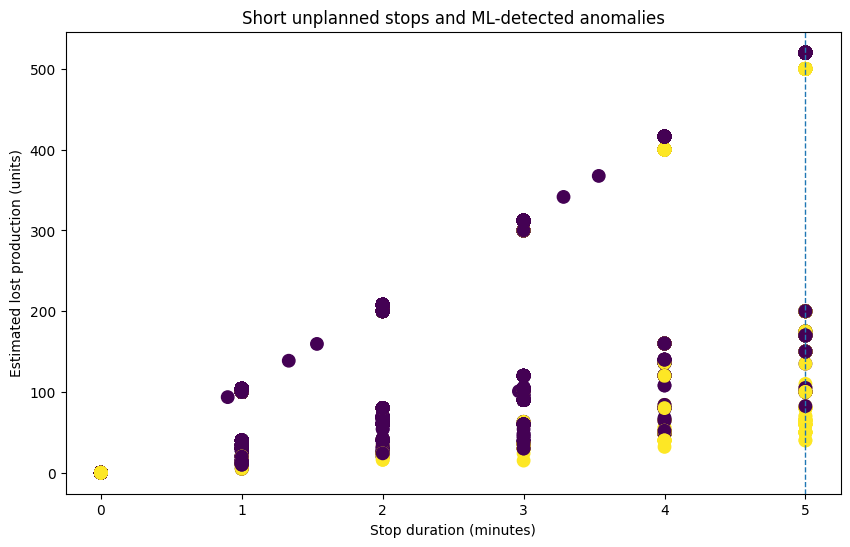

In [10]:

plt.figure(figsize=(10, 6))
plt.scatter(
    stop_candidates["DURACION_MIN"],
    stop_candidates["ESTIMATED_LOSS_UNITS"],
    c=stop_candidates["ML_FLAG"].map({True: 1, False: 0}),
    s=80,
)
plt.axvline(MICROSTOP_MAX_MINUTES, linestyle="--", linewidth=1)
plt.xlabel("Stop duration (minutes)")
plt.ylabel("Estimated lost production (units)")
plt.title("Short unplanned stops and ML-detected anomalies")
plt.show()


## 11. Cuantificación del impacto sobre la producción

En esta etapa se busca determinar el impacto que tienen las posibles microparadas identificadas sobre el proceso productivo. Desde el punto de vista de este trabajo, una microparada adquiere mayor importancia cuando, además de presentar un comportamiento anómalo, **representa una pérdida de producción que puede ser cuantificada**.

Por esta razón, los eventos detectados se ordenan de acuerdo con el número estimado de **unidades que dejaron de producirse** durante cada parada. Esto permite establecer una prioridad entre los eventos y enfocar el análisis en aquellos que podrían generar un mayor impacto sobre el desempeño de la línea.

Posteriormente, las pérdidas estimadas se agrupan considerando diferentes condiciones operativas, principalmente la **línea de producción, el turno y la causa o motivo registrado de la parada**. Este agrupamiento permite identificar patrones y determinar si las pérdidas se concentran en determinadas líneas, turnos o tipos de eventos.

De esta manera, no solo se busca identificar posibles microparadas, sino también **cuantificar su impacto y establecer cuáles deberían ser consideradas prioritarias para futuras acciones de mejora**. Esto permite relacionar directamente los resultados obtenidos mediante el modelo de aprendizaje automático con el desempeño productivo de la línea.


In [11]:

flagged = stop_candidates.loc[stop_candidates["ML_FLAG"]].copy()

impact_by_line = (
    flagged.groupby(["IDLINEA", "LINEA"], dropna=False)
    .agg(
        microstops=("ML_FLAG", "size"),
        downtime_min=("DURACION_MIN", "sum"),
        estimated_loss_units=("ESTIMATED_LOSS_UNITS", "sum"),
        avg_loss_per_stop=("ESTIMATED_LOSS_UNITS", "mean"),
    )
    .sort_values("estimated_loss_units", ascending=False)
)

display(impact_by_line)

impact_by_reason = (
    flagged.groupby("DES_EVENTO", dropna=False)
    .agg(
        microstops=("ML_FLAG", "size"),
        downtime_min=("DURACION_MIN", "sum"),
        estimated_loss_units=("ESTIMATED_LOSS_UNITS", "sum"),
    )
    .sort_values("estimated_loss_units", ascending=False)
)

display(impact_by_reason)


,,microstops,downtime_min,estimated_loss_units,avg_loss_per_stop
IDLINEA,LINEA,,,,
8014,ENVASADO DOYPACK FL 3 3,300,794.0,79400.000002,264.666667
8001,ENVASADO BOTELLA ROTATIVA DESINF,57,242.0,25168.000001,441.543860
8004,ENVASADO BOTELLA OCTOPACK DESINF,166,556.0,16961.999998,102.180723
8009,ENVASADO DOYPACK FL 2 6,146,430.0,8862.000001,60.698630
8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,65,120.0,1631.500000,25.100000


,microstops,downtime_min,estimated_loss_units
DES_EVENTO,,,
Calibracion Preparacion de Linea,340,1329.0,78374.500001
Paradas Operacionales Imprevistas,245,228.0,17296.000000
Fallas de Equipos de Pesaje,22,97.0,9700.000000
Atascamiento de Proceso,11,53.0,4560.000000
Fallas de Codificacion,15,68.0,4372.000000
Falla de fajilladora,22,93.0,3264.000000
Fallas Mecanicas de Procesos,10,35.0,2772.000000
Ausencia de personal,10,27.0,1954.000000
Defectos en material de empaque,13,48.0,1954.000000


## 12. Validación frente al registro de eventos

En esta etapa se busca comprobar si los eventos identificados por el modelo presentan correspondencia con la información registrada en el historial de producción. Para realizar una primera validación, se construye una **etiqueta de referencia** a partir del propio registro de eventos disponible. Esta etiqueta se utiliza únicamente para validar los resultados y **no se incorpora como variable de entrada del modelo**.

Para esta prueba piloto, se considera como referencia un evento que cumpla simultáneamente con dos condiciones: que corresponda a una **parada no planificada** y que su duración sea menor o igual al **umbral seleccionado para definir una microparada**.

Sin embargo, esta estrategia presenta una limitación importante. Debido a que la predicción del modelo se realiza únicamente sobre esta población de eventos candidatos, la comparación con esta referencia permite principalmente realizar una **evaluación de cobertura y un diagnóstico inicial del comportamiento del modelo**, pero no constituye una demostración definitiva de su capacidad para detectar microparadas. En otras palabras, el modelo estaría siendo comparado con una definición construida a partir de los mismos registros que se utilizan durante el análisis.

Para una validación más rigurosa dentro del desarrollo de la tesis, considero más adecuado construir un conjunto de referencia **independiente del modelo**. Para ello, personal con experiencia en producción y mantenimiento podría revisar manualmente una muestra aleatoria de eventos y clasificarlos como `microstop = 1` cuando corresponda a una microparada, o `microstop = 0` cuando no corresponda.

A partir de esta clasificación realizada por expertos, sería posible comparar las predicciones del modelo con una referencia independiente y calcular métricas de evaluación como **precisión (precision), sensibilidad (recall), F1-score y matriz de confusión**. Este procedimiento permitiría obtener una evaluación más objetiva del desempeño del algoritmo y proporcionar un respaldo metodológico más sólido para los resultados presentados en la investigación.

Por lo tanto, la validación con el registro existente se considera una **primera aproximación exploratoria**, mientras que la validación mediante una muestra revisada por expertos constituiría una alternativa más apropiada para sustentar la efectividad del modelo en el contexto de la tesis.


In [12]:

# Diagnostic reference from the source log.
# This is intentionally kept separate from the ML input features.
validation = df.copy()
validation["REFERENCE_MICROSTOP"] = (
    validation["ES_NO_PROGRAMADO"] & validation["DURACION_SEG"].between(0, MICROSTOP_MAX_SECONDS, inclusive="both")
)

validation["MODEL_MICROSTOP"] = False
validation.loc[stop_candidates.index, "MODEL_MICROSTOP"] = stop_candidates["ML_FLAG"]

print("Confusion matrix against the log-derived reference:")
cm = confusion_matrix(validation["REFERENCE_MICROSTOP"], validation["MODEL_MICROSTOP"])
print(cm)

print("\nClassification report:")
print(classification_report(
    validation["REFERENCE_MICROSTOP"],
    validation["MODEL_MICROSTOP"],
    target_names=["not_microstop", "microstop"],
    zero_division=0,
))


Confusion matrix against the log-derived reference:
[[24330     0]
 [ 6600   734]]

Classification report:
               precision    recall  f1-score   support

not_microstop       0.79      1.00      0.88     24330
    microstop       1.00      0.10      0.18      7334

     accuracy                           0.79     31664
    macro avg       0.89      0.55      0.53     31664
 weighted avg       0.84      0.79      0.72     31664




## 13. Validación mediante concordancia temporal con anomalías de producción

Como una segunda estrategia de validación, se propone analizar la **relación temporal entre las posibles microparadas identificadas por el modelo y los eventos que generan un impacto sobre la producción**. Considero que esta validación puede ser más representativa desde el punto de vista operativo, ya que no se limita a verificar si un evento cumple con una definición previamente establecida, sino que busca determinar si existe una relación temporal entre la anomalía detectada y una disminución del desempeño productivo.

La pregunta principal que se busca responder es la siguiente: **cuando el modelo identifica una posible microparada, ¿se presenta inmediatamente antes o después un evento que afecte la producción, o el siguiente período de producción presenta un desempeño inferior al esperado?**

El registro utilizado en este análisis contiene tanto **intervalos correspondientes a paradas como intervalos de producción**. Esta característica permite analizar la secuencia temporal de los eventos y observar qué ocurre alrededor de cada posible microparada detectada por el modelo.

Para realizar esta evaluación, se establece una **ventana de tiempo configurable** alrededor de cada evento identificado. Dentro de dicha ventana se busca el evento de producción más cercano y se analiza su comportamiento. De esta manera, es posible determinar si existe una coincidencia temporal entre la posible microparada y una reducción posterior de la producción o algún otro comportamiento considerado anómalo.

El siguiente bloque de análisis identifica, para cada posible microparada detectada, el **evento de producción más cercano dentro de la ventana temporal definida**. Esta información permite posteriormente comparar la duración de la parada, la pérdida de producción estimada y el desempeño del segmento de producción asociado.

Con este procedimiento se busca aportar una evidencia adicional sobre la relevancia operacional de las anomalías identificadas por el modelo. Si los eventos señalados presentan de manera recurrente una relación temporal con segmentos de producción de bajo desempeño, se puede considerar que existe mayor evidencia para determinar que dichas anomalías están relacionadas con pérdidas reales del proceso productivo.


In [13]:
WINDOW_MINUTES = 5

production_events = (
    df.loc[df["ES_PRODUCCION"], ["IDLINEA", "INICIOEVENTO", "FINEVENTO", "PERFORMANCE_RATIO", "PRODUCCION_PERDIDA_UNIDADES"]]
    .dropna(subset=["INICIOEVENTO"])
    .copy()
)

flagged_events = stop_candidates.loc[stop_candidates["ML_FLAG"], ["IDLINEA", "INICIOEVENTO", "FINEVENTO", "DES_EVENTO", "DURACION_MIN", "ESTIMATED_LOSS_UNITS", "ANOMALY_SCORE"]].copy()
flagged_events = flagged_events.loc[:, ~flagged_events.columns.duplicated()].dropna(subset=["FINEVENTO"]).copy()

if len(flagged_events) and len(production_events):
    merged_parts = []
    for line_id, left_part in flagged_events.groupby("IDLINEA", dropna=False):
        right_part = production_events.loc[production_events["IDLINEA"].eq(line_id)].copy()
        if right_part.empty:
            continue
        left_part = left_part.sort_values("FINEVENTO")
        right_part = right_part.sort_values("INICIOEVENTO")
        tmp = pd.merge_asof(
            left_part, right_part,
            left_on="FINEVENTO", right_on="INICIOEVENTO",
            direction="forward", tolerance=pd.Timedelta(minutes=WINDOW_MINUTES),
            suffixes=("_STOP", "_PROD")
        )
        merged_parts.append(tmp)
    nearest_prod = pd.concat(merged_parts, ignore_index=True) if merged_parts else pd.DataFrame()
    display(nearest_prod.head(20))
else:
    nearest_prod = pd.DataFrame()
    print("Not enough records to run temporal validation.")


,IDLINEA_STOP,INICIOEVENTO_STOP,FINEVENTO_STOP,DES_EVENTO,DURACION_MIN,ESTIMATED_LOSS_UNITS,ANOMALY_SCORE,IDLINEA_PROD,INICIOEVENTO_PROD,FINEVENTO_PROD,PERFORMANCE_RATIO,PRODUCCION_PERDIDA_UNIDADES
0,8001,2025-01-06 07:00:00,2025-01-06 07:04:00,Calibracion Preparacion de Linea,4.0,416.0,0.000021,NaN,NaT,NaT,NaN,NaN
1,8001,2025-01-10 08:30:00,2025-01-10 08:35:00,Calibracion Preparacion de Linea,5.0,520.0,0.013766,8001.0,2025-01-10 08:35:00,2025-01-10 11:00:00,0.861540,2088.933330
2,8001,2025-01-13 13:32:00,2025-01-13 13:37:00,Calibracion Preparacion de Linea,5.0,520.0,0.020296,8001.0,2025-01-13 13:37:00,2025-01-13 13:50:00,0.306268,974.000000
3,8001,2025-01-13 13:50:00,2025-01-13 13:55:00,Calibracion Preparacion de Linea,5.0,520.0,0.020475,8001.0,2025-01-13 13:55:00,2025-01-13 14:33:00,0.804583,779.400000
4,8001,2025-01-15 14:24:00,2025-01-15 14:29:00,Calibracion Preparacion de Linea,5.0,520.0,0.000236,8001.0,2025-01-15 14:29:00,2025-01-15 15:00:00,0.627519,1170.533333
5,8001,2025-01-17 17:11:00,2025-01-17 17:16:00,Falla de llenadora Dosificadora,5.0,520.0,0.003419,NaN,NaT,NaT,NaN,NaN
6,8001,2025-01-17 17:16:00,2025-01-17 17:21:00,Calibracion Preparacion de Linea,5.0,520.0,0.003419,NaN,NaT,NaT,NaN,NaN
7,8001,2025-01-17 17:21:00,2025-01-17 17:26:00,Falla de llenadora Dosificadora,5.0,520.0,0.003668,8001.0,2025-01-17 17:27:00,2025-01-17 18:25:00,0.793269,1247.000000
8,8001,2025-01-18 12:10:00,2025-01-18 12:15:00,Calibracion Preparacion de Linea,5.0,520.0,0.013808,8001.0,2025-01-18 12:15:00,2025-01-18 12:34:00,0.459784,1046.866667
9,8001,2025-01-19 07:21:00,2025-01-19 07:25:00,Calibracion Preparacion de Linea,4.0,416.0,0.001087,8001.0,2025-01-19 07:25:00,2025-01-19 08:05:00,0.668317,1393.600000


## 14. Modelo complementario: detección de intervalos de producción anómalos

Como complemento a la detección de microparadas, se propone analizar únicamente los registros de **producción (`Produccion`)** para identificar intervalos con un comportamiento diferente al normal.

El objetivo es detectar situaciones en las que la línea **continúa produciendo, pero a una velocidad menor a la esperada**, lo que podría representar ciclos lentos o pérdidas de producción que no fueron registradas como una parada independiente.

De esta manera, este análisis complementa al modelo de detección de microparadas y permite identificar otras condiciones que también pueden afectar el desempeño de la línea y, por lo tanto, el OEE.

In [14]:

production = df.loc[df["ES_PRODUCCION"] & df["PR_ESPERADA"].gt(0)].copy()

prod_features = [
    "DURACION_SEG",
    "PRODUCCION",
    "PR_ESPERADA",
    "PERFORMANCE_RATIO",
    "PRODUCCION_PERDIDA_UNIDADES",
    "EXPECTED_RATE_UNITS_HR",
    "VELOCIDADESTANDAR",
    "INCONFORME",
    "TURNO",
    "HORA_INICIO",
    "DIA_SEMANA",
    "MES",
]

Xp = production[prod_features].replace([np.inf, -np.inf], np.nan)
Xp = Xp.fillna(Xp.median(numeric_only=True))

constant_prod_features = [c for c in Xp.columns if Xp[c].nunique(dropna=False) <= 1]
Xp_model = Xp.drop(columns=constant_prod_features)

if len(Xp_model) >= 8:
    iso_prod = IsolationForest(
        n_estimators=300,
        contamination=0.10,
        random_state=RANDOM_STATE,
    )
    iso_prod.fit(Xp_model)
    production["PROD_ANOMALY_SCORE"] = -iso_prod.decision_function(Xp_model)
    production["PROD_ANOMALY"] = (iso_prod.predict(Xp_model) == -1)

    # Prioritize anomalies that also have production below expectation.
    production["RISK_SCORE"] = (
        0.60 * production["PROD_ANOMALY_SCORE"].rank(pct=True)
        + 0.40 * production["PERFORMANCE_LOSS_RATIO"].fillna(0).clip(0, 1)
    )

    low_perf_anomalies = production.loc[
        production["PROD_ANOMALY"] & production["PERFORMANCE_RATIO"].lt(1.0)
    ].sort_values("RISK_SCORE", ascending=False)

    display(
        low_perf_anomalies
        [["IDLINEA", "LINEA", "INICIOEVENTO", "DURACION_MIN", "PRODUCCION", "PR_ESPERADA", "PERFORMANCE_RATIO", "PRODUCCION_PERDIDA_UNIDADES", "RISK_SCORE"]]
    )
else:
    print("Not enough production intervals for a second anomaly-detection model.")


,IDLINEA,LINEA,INICIOEVENTO,DURACION_MIN,PRODUCCION,PR_ESPERADA,PERFORMANCE_RATIO,PRODUCCION_PERDIDA_UNIDADES,RISK_SCORE
9303,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,2025-03-01 19:01:00,211.0,0,3482.600000,0.000000,3482.600000,0.991822
29051,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,2025-04-07 08:01:00,180.0,0,1440.000000,0.000000,1440.000000,0.990373
13268,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,2025-05-09 07:55:00,187.0,0,1497.866667,0.000000,1497.866667,0.989532
29048,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,2025-03-22 11:32:00,181.0,0,1451.466667,0.000000,1451.466667,0.987616
14155,8014,ENVASADO DOYPACK FL 3 3,2025-01-03 07:00:00,53.0,0,5343.333333,0.000000,5343.333333,0.983176
...,...,...,...,...,...,...,...,...,...
3459,8004,ENVASADO BOTELLA OCTOPACK DESINF,2025-01-17 15:17:00,128.0,5083,5132.666667,0.990323,49.666667,0.546062
17763,8009,ENVASADO DOYPACK FL 2 6,2025-04-21 19:26:00,143.0,4258,4280.500000,0.994744,22.500000,0.544949
22981,8009,ENVASADO DOYPACK FL 2 6,2025-05-19 18:44:00,176.0,2109,2112.200000,0.998485,3.200000,0.544854
22313,8009,ENVASADO DOYPACK FL 2 6,2025-01-16 20:26:00,148.0,4415,4437.500000,0.994930,22.500000,0.544033


## 15. Creación de un conjunto de datos para validación humana

Para realizar una validación más confiable, no se debe utilizar únicamente el criterio de duración de la parada como referencia final. En su lugar, se propone crear una tabla de revisión con una muestra de eventos y solicitar a un experto de producción o mantenimiento que los clasifique de manera independiente.

El experto deberá asignar:

- `HUMAN_MICROSTOP_LABEL = 1`: se confirma que el evento corresponde a una microparada que afecta el proceso.
- `HUMAN_MICROSTOP_LABEL = 0`: el evento no corresponde a una microparada.

La clasificación deberá realizarse considerando los **registros de producción, historial de la máquina y criterios operativos**, sin basarse únicamente en la puntuación generada por el modelo.

El conjunto de datos resultante servirá como referencia independiente para evaluar posteriormente el desempeño del modelo mediante métricas como **precision, recall, F1-score y matriz de confusión**.

In [15]:

# Review all currently recorded unplanned events in this pilot.
# For a large real dataset, replace this with a stratified random sample (for example 100-300 events).
review = df.loc[df["ES_NO_PROGRAMADO"]].copy()
review["HUMAN_MICROSTOP_LABEL"] = np.nan
review["VALIDATOR_COMMENT"] = ""

review_cols = [
    "IDLINEA", "LINEA", "DES_EVENTO", "INICIOEVENTO", "FINEVENTO", "DURACION_MIN",
    "TURNO", "ART_CODIGO", "ART_DESCRIPCIÓN", "EXPECTED_RATE_UNITS_HR", "ESTIMATED_LOSS_UNITS",
    "HUMAN_MICROSTOP_LABEL", "VALIDATOR_COMMENT"
]

review_file = os.path.join(OUTPUT_DIR, "microstop_human_validation.xlsx")
review[review_cols].to_excel(review_file, index=False)
print(f"Validation file created: {review_file}")
review[review_cols].head()


Validation file created: /mnt/data/oee_ml_results_tvc2025/microstop_human_validation.xlsx


,IDLINEA,LINEA,DES_EVENTO,INICIOEVENTO,FINEVENTO,DURACION_MIN,TURNO,ART_CODIGO,ART_DESCRIPCIÓN,EXPECTED_RATE_UNITS_HR,ESTIMATED_LOSS_UNITS,HUMAN_MICROSTOP_LABEL,VALIDATOR_COMMENT
10,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,Falta de Prod. Semielaborado Materia Prima,2025-05-05 12:32:00,2025-05-05 13:10:00,38.0,1,110000263.0,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,960.0,608.0,NaN,
23,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,Calibracion Preparacion de Linea,2025-05-10 13:04:00,2025-05-10 13:19:00,15.0,1,110000263.0,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,960.0,240.0,NaN,
24,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,Falla de cadena de arrastre,2025-04-03 23:00:00,2025-04-03 23:00:00,0.0,3,110000263.0,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,960.0,0.0,NaN,
26,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,Calibracion Preparacion de Linea,2025-03-07 15:02:00,2025-03-07 15:06:00,4.0,2,110000263.0,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,960.0,64.0,NaN,
28,8005,ENVASADO BOTELLA TOZZOMY KALISH DET SUAV,Paradas Operacionales Imprevistas,2025-03-12 10:00:00,2025-03-12 10:00:00,0.0,1,110000263.0,SUAVZ PERLA PRIMV.FLOR P'ESP BOT*1L*6,960.0,0.0,NaN,


## 16. Entrenamiento de un modelo supervisado después de la validación humana

Una vez que los expertos hayan completado la validación en `microstop_human_validation.xlsx`, se puede utilizar esta información para entrenar un **modelo de aprendizaje supervisado**. De esta manera, el modelo aprenderá a partir de los eventos que fueron previamente validados como microparadas o no microparadas.

Para esta etapa se propone utilizar **Random Forest**, ya que permite trabajar con relaciones no lineales y diferentes tipos de variables operativas. Este enfoque sería más adecuado para una implementación final que depender permanentemente de un modelo de detección de anomalías no supervisado.

Al igual que en las etapas anteriores, las variables de descripción y clasificación del evento se mantienen fuera de las variables predictoras para evitar **fuga de información (label leakage)** y asegurar que el modelo aprenda a partir de las características reales de operación.

In [16]:

LABELED_FILE = os.path.join(OUTPUT_DIR, "microstop_human_validation.xlsx")

if os.path.exists(LABELED_FILE):
    labeled = pd.read_excel(LABELED_FILE)
    labeled = labeled.dropna(subset=["HUMAN_MICROSTOP_LABEL"]).copy()
else:
    labeled = pd.DataFrame()

if len(labeled) >= 20 and labeled["HUMAN_MICROSTOP_LABEL"].nunique() == 2:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import train_test_split
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

    features = [
        "DURACION_MIN", "TURNO", "EXPECTED_RATE_UNITS_HR", "ESTIMATED_LOSS_UNITS",
        "IDLINEA", "ART_CODIGO"
    ]
    X = labeled[features].copy()
    y = labeled["HUMAN_MICROSTOP_LABEL"].astype(int)

    num_features = ["DURACION_MIN", "TURNO", "EXPECTED_RATE_UNITS_HR", "ESTIMATED_LOSS_UNITS"]
    cat_features = ["IDLINEA", "ART_CODIGO"]

    preprocessor = ColumnTransformer([
        ("num", "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
    )

    clf = Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            min_samples_leaf=2,
        )),
    ])

    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    prob = clf.predict_proba(X_test)[:, 1]

    print("Confusion matrix:")
    print(confusion_matrix(y_test, pred))
    print("\nClassification report:")
    print(classification_report(y_test, pred, digits=3, zero_division=0))
    print(f"ROC AUC: {roc_auc_score(y_test, prob):.3f}")
else:
    print("Supervised model not executed yet.")
    print("Complete HUMAN_MICROSTOP_LABEL with both 0 and 1 labels in microstop_human_validation.xlsx, then rerun this cell.")


Supervised model not executed yet.
Complete HUMAN_MICROSTOP_LABEL with both 0 and 1 labels in microstop_human_validation.xlsx, then rerun this cell.


## 17. Criterios para determinar una validación exitosa

Para evaluar el desempeño del modelo en la tesis, se considerarán diferentes métricas de clasificación. Estas permitirán determinar qué tan bien el modelo identifica las microparadas reales.

- **Precision:** indica qué proporción de los eventos identificados como microparadas realmente lo son.
- **Recall:** indica qué proporción de las microparadas reales logra detectar el modelo.
- **F1-score:** permite analizar conjuntamente el precision y el recall.
- **ROC AUC:** permite evaluar la capacidad del modelo para diferenciar entre microparadas y eventos que no corresponden a ellas.
- **Matriz de confusión:** permite observar los aciertos y errores del modelo mediante verdaderos positivos, falsos positivos, verdaderos negativos y falsos negativos.



Además, considero importante comparar los resultados del modelo de aprendizaje automático con una **regla operativa básica**, por ejemplo, considerar como microparada cualquier evento cuya duración sea menor o igual al umbral establecido. Esta comparación permitirá determinar si el uso de aprendizaje automático realmente aporta una mejora frente a un criterio sencillo basado únicamente en la duración del evento.

## 15. Exportación de los resultados

Finalmente, los resultados obtenidos durante el análisis pueden exportarse en formatos **CSV o Excel**. Estos archivos pueden utilizarse posteriormente para alimentar herramientas de visualización y generación de reportes, como **Looker Studio, BigQuery u otras plataformas de análisis**.

De esta manera, los resultados del modelo pueden integrarse con el sistema de análisis de datos y facilitar su consulta y visualización para el seguimiento del desempeño de la línea de producción.


In [17]:

OUTPUT_DIR = "/mnt/data/oee_ml_results_tvc2025"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ranked_microstops.to_csv(os.path.join(OUTPUT_DIR, "microstop_candidates_ranked.csv"), index=False)
impact_by_line.to_csv(os.path.join(OUTPUT_DIR, "microstop_impact_by_line.csv"))
impact_by_reason.to_csv(os.path.join(OUTPUT_DIR, "microstop_impact_by_reason.csv"))

if "production" in globals() and "RISK_SCORE" in production.columns:
    production.to_csv(os.path.join(OUTPUT_DIR, "production_anomalies.csv"), index=False)

print(f"Results saved in: {OUTPUT_DIR}/")


Results saved in: /mnt/data/oee_ml_results_tvc2025/
